<a href="https://colab.research.google.com/github/EpiPandit/MPM_200_2026/blob/main/session%203/Introduction_to_R.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🐄 R Quest: Your First Day as a Data Detective
**MPM 200 · Week 1 · Introduction to R** · UC Davis School of Veterinary Medicine

> **The story.** It's August 2020. You've just joined a state public-health team as the new epidemiologist. Your supervisor drops a file on your desk (five months of daily COVID-19 reports from every US state and territory) and says: *"Tell me what's in here by Friday."*
>
> You've never used R. By the end of this notebook you will have loaded, cleaned, summarized and plotted that data, and drawn California's epidemic curve.

**How the quest works**

| | |
|---|---|
| 🧭 **6 levels + a boss level** | Each one adds a single new skill. Run the cells in order. |
| 🔮 **Predict first** | Before some cells, jot down a guess. Being wrong is where the learning happens. |
| 🎯 **Your turn** | Short challenges. These cells have blanks (`____`), so they won't run until you fill them in. |
| 💡 **Hints** | Hidden in toggles. Try for two minutes before you peek. |
| 🐛 **Bug hunt** | Errors are normal. Reading them is a skill, and we'll practise it. |

## 🚀 Level 0 · Set up Colab (2 minutes)

1. Open this notebook with the **Open in Colab** badge and sign in with your **UC Davis** Google account.
2. **Runtime → Change runtime type → R**. Leave hardware on CPU.
3. **File → Save a copy in Drive** so the edits are yours (copies land in *My Drive / Colab Notebooks*).
4. Run a cell with **Shift + Enter**.
5. Colab forgets everything (installed packages, uploaded files, objects) when the runtime disconnects. When you come back, run the cells from the top again.

If the next cell prints an R version, you're in. 🎉

In [1]:
R.version.string

[1] "R version 4.6.1 (2026-06-24)"

## 🧮 Level 1 · R is a very fancy calculator

R evaluates whatever you type. To keep a result, store it in an **object** with `<-` (you'll also see `=`; both work).
Anything after `#` is a comment: R ignores it, humans love it.

In [2]:
2 + 2
12 * 7        # dogs in the ward × doses per day
sqrt(144)

[1] 4

[1] 84

[1] 12

In [3]:
n_cats <- 14          # an object holding a number
n_dogs <- 9
n_cats + n_dogs

[1] 23

### What kind of thing is it? Data types
R treats text, numbers and TRUE/FALSE differently. `class()` tells you what you have.

In [4]:
patient    <- "Biscuit"   # character (text) needs quotes
weight_kg  <- 4.2         # numeric
vaccinated <- TRUE        # logical: TRUE or FALSE

class(patient)
class(weight_kg)
class(vaccinated)

[1] "character"

[1] "numeric"

[1] "logical"

### Vectors: many values in one object
`c()` **c**ombines values. Most R functions work on a whole vector at once, with no loops needed.

In [5]:
ward_weights <- c(4.2, 5.1, 3.8, 6.0, 4.9)   # five cats, in kg

mean(ward_weights)
max(ward_weights)
ward_weights * 2.2      # kg → lb, all five at once
ward_weights > 5        # which cats weigh more than 5 kg?

[1] 4.8

[1] 6

[1]  9.24 11.22  8.36 13.20 10.78

[1] FALSE  TRUE FALSE  TRUE FALSE

### 🎯 Your turn
Create a vector called `species` with the last **six** patients seen at the VMTH (repeats are fine, e.g. `"dog", "cat", "dog", ...`).
1. How many patients? Use `length()`.
2. How many of each species? Use `table()`.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

`species <- c("dog", "cat", "dog", "horse", "cat", "dog")` then `length(species)` and `table(species)`

</details>

In [6]:
species <- c(____)
length(____)
table(____)

ERROR: Error in parse(text = input): <text>:1:15: unexpected input
1: species <- c(__
                  ^


## 📦 Level 2 · Packages: R's app store

A **package** is a bundle of functions somebody else wrote and shared. Using one takes two steps:

| Step | Command | How often |
|---|---|---|
| **Install** (download it) | `install.packages("name")` | Once per laptop. **Once per session on Colab** (it forgets). |
| **Load** (switch it on) | `library(name)` | Every session |

Let's install a very serious scientific package.

In [7]:
install.packages("cowsay")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



Every function has a help page. `?function_name` opens it. Read the **Arguments** and **Examples** sections, and get into the habit of doing this for every new function you meet.

In [8]:
?install.packages

In [10]:
library(cowsay)
say("Hello, MPVM class! Welcome to R.", by = "cow")


 __________________________________ 
< Hello, MPVM class! Welcome to R. >
 ---------------------------------- 
      \
       \

        ^__^ 
        (oo)\ ________ 
        (__)\         )\ /\ 
             ||------w|
             ||      ||

In [11]:
?say
names(animals)   # every animal cowsay knows

NULL

### 🎯 Your turn
1. Make the **bat** say something nice about bats (they eat a *lot* of insects).
2. Pick your favourite animal from `names(animals)` and have it introduce **you**.
3. Bonus: try the `what_color` and `by_color` arguments (e.g. `"blue"`, `"yellow"`). Colors may not show in every viewer; that's fine.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

`say("Bats are pest control with wings!", by = "bat", what_color = "blue", by_color = "red")`

</details>

In [12]:
say("____", by = "bat")


 ______ 
|  ____|
 ------ 
               \
                \

        __.--'\     \.__./     /'--.__
    _.-'       '.__.'    '.__.'       '-._
  .'                                      '.
 /                                          \
|                                            |
|                                            |
 \         .---.              .---.         /
  '._    .'     '.''.    .''.'     '.    _.'
     '-./            \  /           \.-'
                      ''mrf

## 🗂️ Level 3 · Know where you are: the working directory

R reads and writes files relative to a **working directory**. On Colab it is `/content`. Click the 📁 folder icon on the left to see it.

In [13]:
getwd()

[1] "/content"

In [14]:
list.files()     # what is in here right now?

[1] "sample_data"

Remember the lecture: **protect raw data and keep outputs separate.** Let's build a tiny, tidy project.

In [15]:
dir.create("data_raw", showWarnings = FALSE)
dir.create("outputs",  showWarnings = FALSE)
list.files()

[1] "data_raw"    "outputs"     "sample_data"

> **About `setwd()`.** It changes the working directory. On your laptop it might be `setwd("C:/Users/you/MPM200")` (Windows) or `setwd("~/MPM200")` (Mac).
> A path from *someone else's* computer will always fail on yours, so copy-pasting `setwd("C:/Users/prana/...")` won't work. On Colab we stay in `/content` and use **relative paths** like `"outputs/plot.pdf"`.

### Your environment: which objects exist?

In [16]:
ls()

[1] "n_cats"       "n_dogs"       "patient"      "vaccinated"   "ward_weights"
[6] "weight_kg"

In [17]:
rm(list = ls())   # deletes ALL objects. There is no undo!
ls()              # empty again

character(0)

## 🔍 Level 4 · Meet the data

The **COVID Tracking Project** was a volunteer effort that compiled daily state-level reports during 2020–21. Our file is a snapshot up to **7 August 2020**: one row per state (or territory) per day.

We download it straight from the course GitHub into `data_raw/` (no upload needed), then read it.

In [19]:
library(dplyr)
library(ggplot2)

url <- "https://raw.githubusercontent.com/EpiPandit/MPM_200_2026/main/data/covid-tracking-data-master_COVID_Tracking_Project_2020_08_07_daily.csv"
download.file(url, destfile = "data_raw/covid_tracking_20200807.csv")

COVID <- read.csv("data_raw/covid_tracking_20200807.csv")

### 🔮 Predict first
One row per state per day, about 56 states and territories, about five months of reports.
**Roughly how many rows do you expect?** Write your guess here: `____`

In [20]:
dim(COVID)      # rows, columns
nrow(COVID)
ncol(COVID)

[1] 8697   41

[1] 8697

[1] 41

In [21]:
head(COVID)    # first 6 rows

,date,state,positive,negative,pending,hospitalizedCurrently,hospitalizedCumulative,inIcuCurrently,inIcuCumulative,onVentilatorCurrently,⋯,posNeg,deathIncrease,hospitalizedIncrease,hash,commercialScore,negativeRegularScore,negativeScore,positiveScore,score,grade
,<int>,<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,⋯,<int>,<int>,<int>,<chr>,<int>,<int>,<int>,<int>,<int>,<lgl>
1,20200807,AK,4288,264563,NA,37,NA,NA,NA,3,⋯,268851,0,0,d608cee3e98d23a9e920faab4361b771c779880f,0,0,0,0,0,NA
2,20200807,AL,98301,651115,NA,1575,11537,NA,1219,NA,⋯,749416,21,224,b180d67ecb2784ceaaaf7fef67dcee5833fadd52,0,0,0,0,0,NA
3,20200807,AR,48039,503484,NA,514,3168,NA,NA,111,⋯,551523,6,50,1e9a8ed04dc081a895e26f03a10711ce88d78be2,0,0,0,0,0,NA
4,20200807,AS,0,1396,NA,NA,NA,NA,NA,NA,⋯,1396,0,0,9395052fa25b89c3561068bed6cc6c425623bb9c,0,0,0,0,0,NA
5,20200807,AZ,185053,819792,NA,1772,19241,565,NA,411,⋯,1004845,79,5173,73a278d71ae7e87e4e634538a146339f015d5531,0,0,0,0,0,NA
6,20200807,CA,538416,8058466,NA,7277,NA,1978,NA,NA,⋯,8596882,142,0,de76be81f6dc15ca6c65b81d94e2c5e34e4489df,0,0,0,0,0,NA


In [22]:
colnames(COVID)

[1] "date"                     "state"                   
 [3] "positive"                 "negative"                
 [5] "pending"                  "hospitalizedCurrently"   
 [7] "hospitalizedCumulative"   "inIcuCurrently"          
 [9] "inIcuCumulative"          "onVentilatorCurrently"   
[11] "onVentilatorCumulative"   "recovered"               
[13] "dataQualityGrade"         "lastUpdateEt"            
[15] "dateModified"             "checkTimeEt"             
[17] "death"                    "hospitalized"            
[19] "dateChecked"              "totalTestsViral"         
[21] "positiveTestsViral"       "negativeTestsViral"      
[23] "positiveCasesViral"       "deathConfirmed"          
[25] "deathProbable"            "fips"                    
[27] "positiveIncrease"         "negativeIncrease"        
[29] "total"                    "totalTestResults"        
[31] "totalTestResultsIncrease" "posNeg"                  
[33] "deathIncrease"            "hospitalizedIncrease"    
[35] "hash"                     "commercialScore"         
[37] "negativeRegularScore"     "negativeScore"           
[39] "positiveScore"            "score"                   
[41] "grade"

In [23]:
str(COVID)     # structure: the type of every column

'data.frame':	8697 obs. of  41 variables:
 $ date                    : int  20200807 20200807 20200807 20200807 20200807 20200807 20200807 20200807 20200807 20200807 ...
 $ state                   : chr  "AK" "AL" "AR" "AS" ...
 $ positive                : int  4288 98301 48039 0 185053 538416 49436 50320 12589 15445 ...
 $ negative                : int  264563 651115 503484 1396 819792 8058466 521927 814313 196136 179339 ...
 $ pending                 : int  NA NA NA NA NA NA NA NA NA NA ...
 $ hospitalizedCurrently   : int  37 1575 514 NA 1772 7277 317 65 90 37 ...
 $ hospitalizedCumulative  : int  NA 11537 3168 NA 19241 NA 6572 10920 NA NA ...
 $ inIcuCurrently          : int  NA NA NA NA 565 1978 NA NA 18 15 ...
 $ inIcuCumulative         : int  NA 1219 NA NA NA NA NA NA NA NA ...
 $ onVentilatorCurrently   : int  3 NA 111 NA 411 NA NA NA 12 NA ...
 $ onVentilatorCumulative  : int  NA 658 429 NA NA NA NA NA NA NA ...
 $ recovered               : int  1238 37923 40360 NA 24815 NA 54

### One column at a time: `$`
`data$column` pulls a single column out as a vector.

In [ ]:
head(COVID$state, 20)

In [ ]:
COVID$state <- as.factor(COVID$state)   # text → categories (factor)
levels(COVID$state)
length(unique(COVID$state))             # how many states + territories?

In [ ]:
table(COVID$state)    # rows per state

🤔 **Think:** almost every state has about 155 rows, but **WA has 199**. What does that tell you about *when* Washington started reporting? (Hint: where was the first US case detected?)

### Missing values (`NA`)
`is.na()` returns TRUE where a value is missing. TRUE counts as 1, so `sum()` counts the gaps.

In [24]:
sum(is.na(COVID$state))                   # state is never missing
sum(is.na(COVID$hospitalizedCurrently))   # hospitalization often is

[1] 0

[1] 2603

In [25]:
colSums(is.na(COVID))   # missing values in every column at once

date                    state                 positive 
                       0                        0                       15 
                negative                  pending    hospitalizedCurrently 
                     156                     7599                     2603 
  hospitalizedCumulative           inIcuCurrently          inIcuCumulative 
                    3993                     5538                     7417 
   onVentilatorCurrently   onVentilatorCumulative                recovered 
                    5948                     8243                     3235 
        dataQualityGrade             lastUpdateEt             dateModified 
                       0                        0                        0 
             checkTimeEt                    death             hospitalized 
                       0                      698                     3993 
             dateChecked          totalTestsViral       positiveTestsViral 
                       0                     5300                     7557 
      negativeTestsViral       positiveCasesViral           deathConfirmed 
                    7524                     3052                     5530 
           deathProbable                     fips         positiveIncrease 
                    6720                        0                        0 
        negativeIncrease                    total         totalTestResults 
                       0                        0                        0 
totalTestResultsIncrease                   posNeg            deathIncrease 
                       0                        0                        0 
    hospitalizedIncrease                     hash          commercialScore 
                       0                        0                        0 
    negativeRegularScore            negativeScore            positiveScore 
                       0                        0                        0 
                   score                    grade 
                       0                     8697

### 🎯 Your turn
Which **three** columns have the most missing data? Would you trust an analysis built on them?

<details><summary>💡 <b>Hint</b> (try first!)</summary>

`sort(colSums(is.na(COVID)), decreasing = TRUE)[1:3]`

</details>

In [26]:
# your code here

### 🐛 Bug hunt: round brackets vs square brackets
Rows and columns are picked with **square** brackets: `data[row, column]`. **Round** brackets `()` *call functions*.

Remove the `#` in the next cell, run it, and read the error message. What is R telling you? Then fix it.

In [27]:
# COVID(1, 2)    # 🐛 I want row 1, column 2

In [28]:
COVID[1, 2]                                   # the fix
COVID[1:3, c("date", "state", "positive")]    # rows 1–3, three named columns

[1] "AK"

,date,state,positive
,<int>,<chr>,<int>
1,20200807,AK,4288
2,20200807,AL,98301
3,20200807,AR,48039


### Subsetting rows: California only

In [29]:
CA <- COVID[COVID$state == "CA", ]
dim(CA)
head(CA[, c("date", "state", "positive", "positiveIncrease")])

[1] 157  41

,date,state,positive,positiveIncrease
,<int>,<chr>,<int>,<int>
6,20200807,CA,538416,8436
62,20200806,CA,529980,5258
118,20200805,CA,524722,5295
174,20200804,CA,519427,4526
230,20200803,CA,514901,5739
286,20200802,CA,509162,9032


## 🧰 Level 5 · Wrangling with dplyr

Four verbs do most of the work in data management:

| Verb | What it does |
|---|---|
| `select()` | keep some **columns** |
| `filter()` | keep some **rows** |
| `group_by()` | split the data into groups |
| `summarise()` | collapse each group into a summary |

The pipe `%>%` reads as **"and then"**. (RStudio shortcut: Ctrl/Cmd + Shift + M. Base R also has `|>`.)

In [30]:
COVID %>%
  select(date, state, positive, positiveIncrease) %>%
  head()

,date,state,positive,positiveIncrease
,<int>,<chr>,<int>,<int>
1,20200807,AK,4288,65
2,20200807,AL,98301,1709
3,20200807,AR,48039,1011
4,20200807,AS,0,0
5,20200807,AZ,185053,1406
6,20200807,CA,538416,8436


In [31]:
COVID %>%
  filter(state == "CA", date >= 20200801) %>%     # dates are stored as numbers like 20200807
  select(date, state, positiveIncrease)

date,state,positiveIncrease
<int>,<chr>,<int>
20200807,CA,8436
20200806,CA,5258
20200805,CA,5295
20200804,CA,4526
20200803,CA,5739
20200802,CA,9032
20200801,CA,6542


### Total cases per state
Two columns look similar, but they mean different things:
* `positive`: the **cumulative** count (running total so far)
* `positiveIncrease`: **new** cases reported that day (incidence)

Summing the daily new cases gives the total. Let's check that against the last cumulative value.

🔮 **Predict first:** which **five** states had the most reported cases by 7 August 2020? `____, ____, ____, ____, ____`

In [32]:
total_cases <- COVID %>%
  group_by(state) %>%
  summarise(total_cases     = sum(positiveIncrease, na.rm = TRUE),
            last_cumulative = max(positive, na.rm = TRUE)) %>%
  arrange(desc(total_cases))

head(total_cases, 5)

state,total_cases,last_cumulative
<chr>,<int>,<int>
CA,538363,538416
FL,518073,518075
TX,474523,474524
NY,419636,419642
GA,209002,209004


🤔 The two columns are *almost* equal, but not quite. Why might a running total disagree slightly with the sum of daily reports? (Think: corrections and back-filled data.)

### 🎯 Your turn
Which five states had reported the most **deaths**? Use the `deathIncrease` column.

<details><summary>💡 <b>Hint</b> (try first!)</summary>


```r
COVID %>%
  group_by(state) %>%
  summarise(total_deaths = sum(deathIncrease, na.rm = TRUE)) %>%
  arrange(desc(total_deaths)) %>%
  head(5)
```

</details>

In [33]:
COVID %>%
  group_by(____) %>%
  summarise(total_deaths = sum(____, na.rm = TRUE)) %>%
  arrange(desc(____)) %>%
  head(5)

ERROR: Error in parse(text = input): <text>:2:13: unexpected input
1: COVID %>%
2:   group_by(__
               ^


### Save your summary table (`row.names = FALSE` keeps R's row numbers out of the file)

In [34]:
write.csv(total_cases, "outputs/total_cases_by_state.csv", row.names = FALSE)
list.files("outputs")

[1] "total_cases_by_state.csv"

## 🎨 Level 6 · ggplot2: build a plot one layer at a time

ggplot2 follows the **grammar of graphics**: **data** + **aes**thetics (what goes on which axis) + **geom**etry (bars, points, lines) + extras. Layers are added with `+`.
Run these cells one at a time and watch the plot grow.

In [35]:
options(repr.plot.width = 7, repr.plot.height = 8)   # plot size in Colab

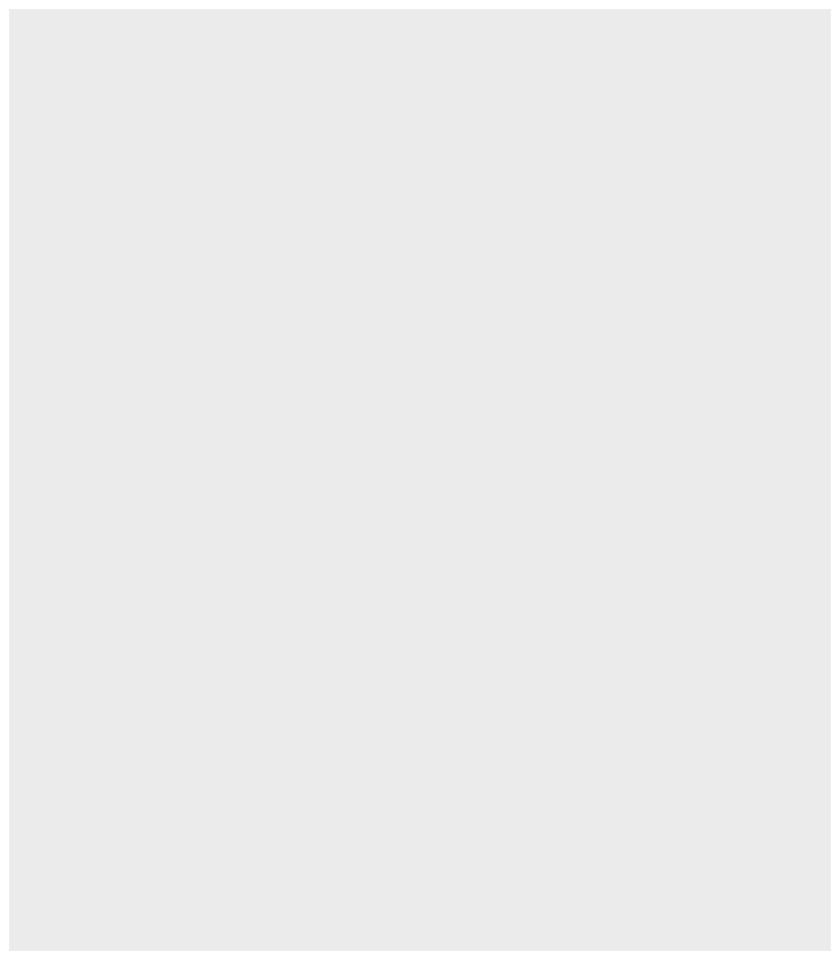

In [36]:
ggplot(total_cases)                                     # 1. an empty canvas

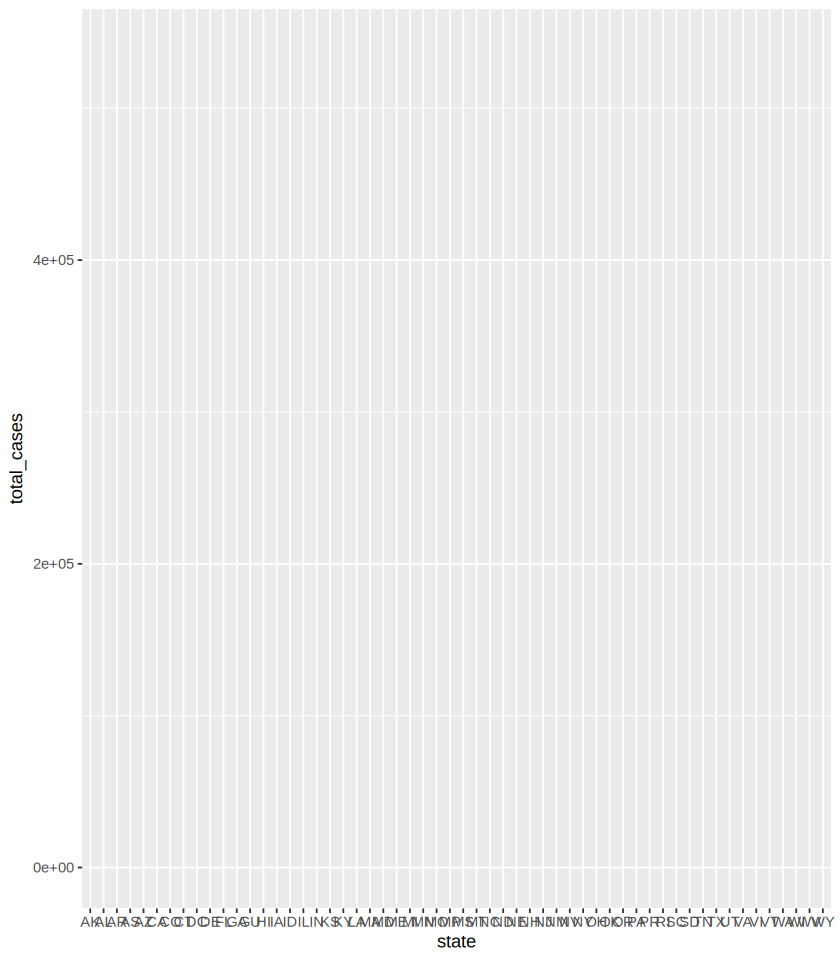

In [37]:
ggplot(total_cases, aes(x = state, y = total_cases))    # 2. axes mapped

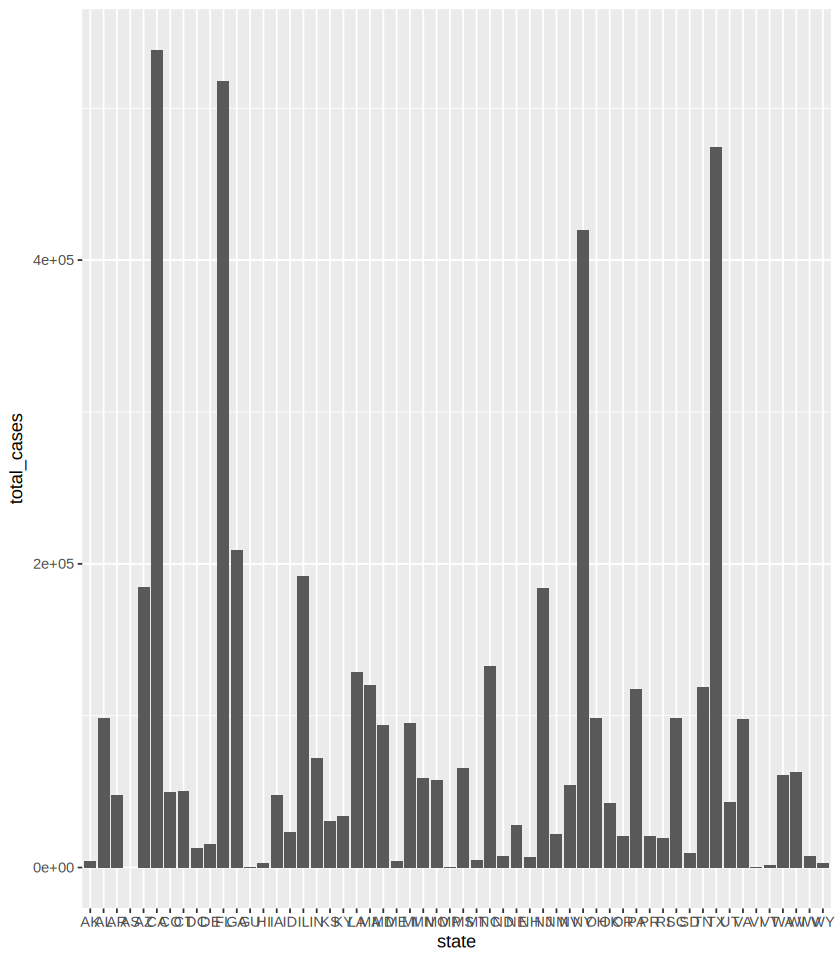

In [38]:
ggplot(total_cases, aes(x = state, y = total_cases)) +
  geom_col()                                               # 3. bars

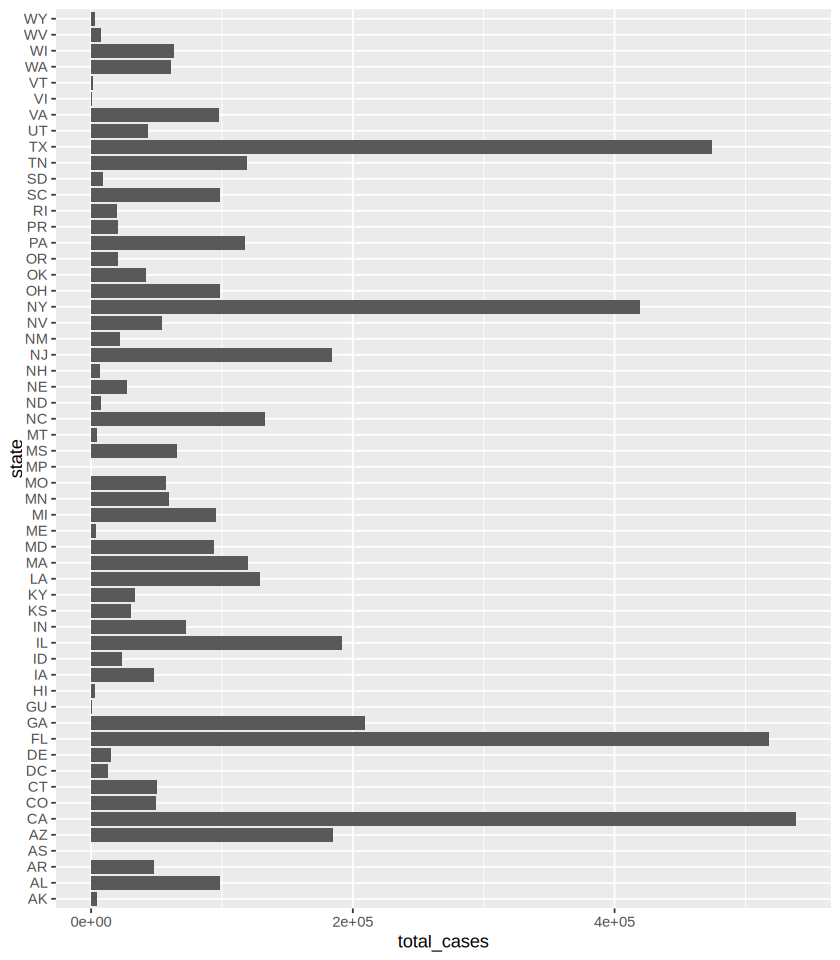

In [39]:
ggplot(total_cases, aes(x = state, y = total_cases)) +
  geom_col() +
  coord_flip()                                             # 4. readable labels

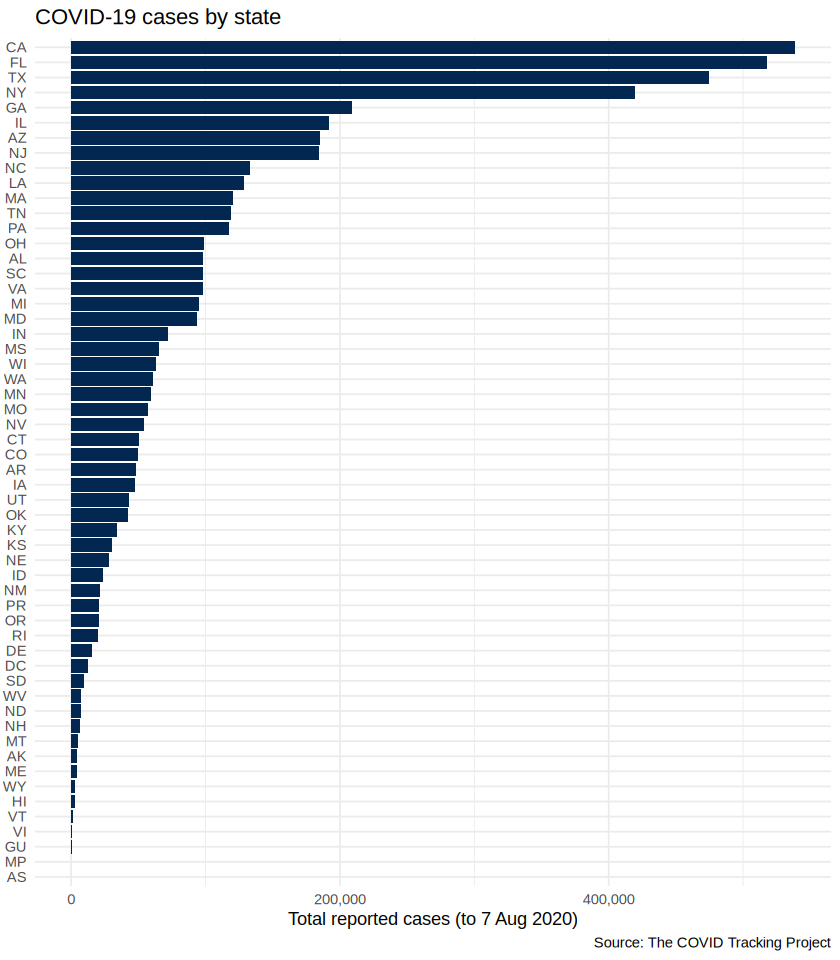

In [40]:
p <- ggplot(total_cases, aes(x = reorder(state, total_cases), y = total_cases)) +
  geom_col(fill = "#022851") +                             # 5. Aggie Blue, sorted
  coord_flip() +
  scale_y_continuous(labels = scales::comma) +
  labs(x = NULL,
       y = "Total reported cases (to 7 Aug 2020)",
       title = "COVID-19 cases by state",
       caption = "Source: The COVID Tracking Project") +
  theme_minimal(base_size = 11)
p

Prefer points to bars? Swap one layer: `geom_point(colour = "#022851", size = 2)`. Try it!

### Save the plot

In [41]:
ggsave("outputs/cases_by_state.pdf", p, width = 6, height = 8)
list.files("outputs")

[1] "cases_by_state.pdf"       "total_cases_by_state.csv"

⬇️ **Download it:** 📁 → `outputs` → ⋮ next to the file → **Download**. Remember that Colab files vanish when the runtime disconnects.

### 🎯 Glow-up challenge
Make California stand out in **Aggie Gold** (`#FFBF00`) while every other state stays Aggie Blue.

<details><summary>💡 <b>Hint</b> (try first!)</summary>


Map the fill to a TRUE/FALSE question, then choose the two colours:
```r
ggplot(total_cases, aes(x = reorder(state, total_cases), y = total_cases,
                        fill = state == "CA")) +
  geom_col() +
  coord_flip() +
  scale_fill_manual(values = c("#022851", "#FFBF00"), guide = "none")
```

</details>

In [42]:
# your glow-up here

## 👾 Boss level · Draw California's epidemic curve

An **epi curve** plots new cases over time. It is the single most-used chart in outbreak investigation.
Dates are stored as numbers like `20200807`, so first we turn them into real `Date` objects.

In [43]:
CA <- COVID %>%
  filter(state == "CA") %>%
  mutate(date = as.Date(as.character(date), format = "%Y%m%d")) %>%
  arrange(date)

class(CA$date)
range(CA$date)

[1] "Date"

[1] "2020-03-04" "2020-08-07"

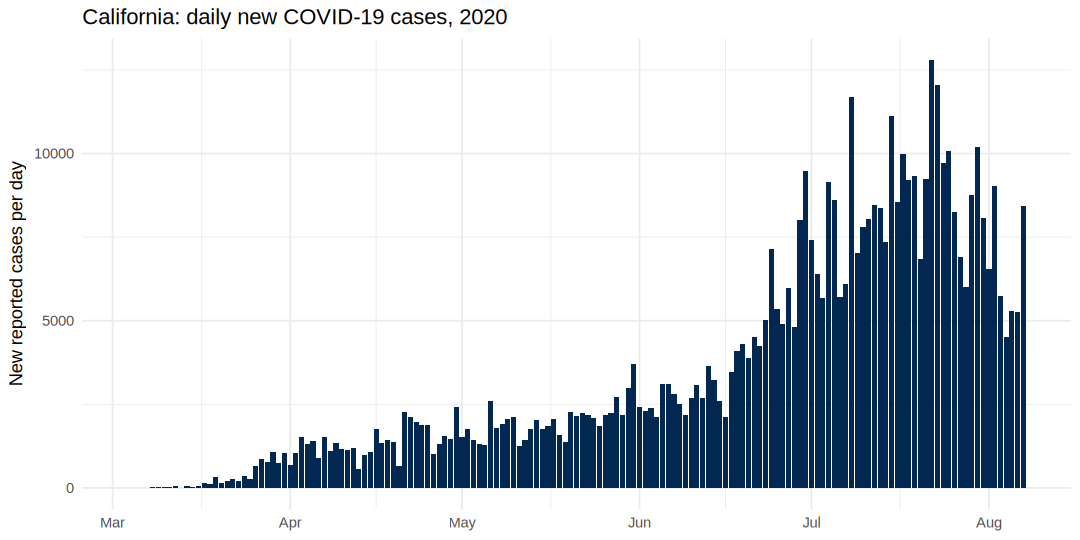

In [44]:
options(repr.plot.width = 9, repr.plot.height = 4.5)

ggplot(CA, aes(x = date, y = positiveIncrease)) +
  geom_col(fill = "#022851") +
  labs(x = NULL, y = "New reported cases per day",
       title = "California: daily new COVID-19 cases, 2020") +
  theme_minimal()

### 🎯 Final challenges (pick at least one)
1. **Smooth it.** Daily reports are noisy (weekends!). Add a 7-day rolling average line in Aggie Gold.
2. **Go home.** Draw the epi curve for your home state, or any state you're curious about.
3. **Detective.** Some states have *negative* daily increases. Find them with `filter(COVID, positiveIncrease < 0)`. How can new cases be negative? What does that tell you about surveillance data?

<details><summary>💡 <b>Hint</b> (try first!)</summary>


Rolling average (note `stats::filter`, because dplyr has its own `filter()`):
```r
CA <- CA %>%
  mutate(avg7 = as.numeric(stats::filter(positiveIncrease, rep(1/7, 7), sides = 1)))

ggplot(CA, aes(x = date, y = positiveIncrease)) +
  geom_col(fill = "#022851") +
  geom_line(aes(y = avg7), colour = "#FFBF00", linewidth = 1.2) +
  theme_minimal()
```

</details>

In [45]:
# boss-level code here

In [46]:
say("Quest complete! You loaded, wrangled, plotted and saved real surveillance data.", by = "chicken")


 _________________________________________________________ 
/ Quest complete! You loaded, wrangled, plotted and saved \
\ real surveillance data.                                 /
 --------------------------------------------------------- 
      \
       \
         _
       _/ }
      `>' \
      `|   \
       |   /'-.     .-.
        \'     ';`--' .'
         \'.    `'-./
          '.`-..-;`
            `;-..'
            _| _|
            /` /` [nosig]

## 🏁 Before you log off
- **Save your work:** File → Save a copy in Drive, *or* File → Save a copy in GitHub → **your own branch** (never `main`).
- **Download anything you need** from `outputs/`.
- **Cheat sheets worth bookmarking:** [dplyr](https://rstudio.github.io/cheatsheets/data-transformation.pdf) · [ggplot2](https://rstudio.github.io/cheatsheets/data-visualization.pdf)

Next up: the Week 1 assignment, **🐦 Will the Hummers Survive?**